### **ASIGNATURA:** GESTION DE PROYECTOS

### **NOMBRE PROYECTO:** Análisis de factores de riesgo de enfermedad cardíaca

### **FECHA:** 23 de noviembre 2026

### **NOMBRE INTEGRANTES:**
- Matías Turra
- Benjamin Neira
- Gustavo Alvial



## **Objetivo General**

Construir un modelo de machine learning que permita identificar los principales factores asociados al riesgo cardiovascular en pacientes atendidos en controles preventivos, generando herramientas de apoyo para la priorización, el monitoreo y la toma de decisiones en pacientes de mayor riesgo.

## **Objetivo Específicos**

* Desarrollar un modelo que estime la probabilidad de riesgo cardiovascular por paciente, prestando especial atención en los falsos negativos y a posibles diferencias de desempeño entre grupos de pacientes, buscando asegurar una sensibilidad mínima del 90% para la identificación de pacientes de alto riesgo.
* Desarrollar un panel de indicadores clínicos que permitan al equipo de salud monitorear los principales factores de riesgo y sea aprobado por los usuarios de la Unidad de Cardiología Preventiva.
* Capacitar al personal definido por el proyecto en el uso e interpretación de la información entregada por la solución, alcanzando por lo menos un 80% en la participación de los usuarios convocados.


##**Problema**

La falta de herramientas tecnológicas para análisis de factores de riesgo cardiovasculares dentro del establecimiento médico Hospital público regional de los robles limita la capacidad de priorizar atenciones médicas, Esta problemática lleva a implementar en el establecimiento una solucion analitica que mejore la  detección temprana de anomalías cardiacas a pacientes y optimizar la gestión de recursos dentro del sistema.

##**Contexto de la Data**

* **Período:**
* **Formato:** CSV
* **Contexto de Datos:**

* **Archivo:**


## METODOLOGÍA UTILIZADA EN EL PROYECTO DE CIENCIA DE DATOS
##NOMBRE: CRISP-DM

1. Proporciona un enfoque estructurado y confiable para proyectos de ciencia de datos, facilitando el trabajo colaborativo y asegurando consistencia en los procesos.

2. Permite iterar y ajustarse a cambios en los datos, requisitos o descubrimientos durante el desarrollo del proyecto.

3. Es adaptable a cualquier industria o tipo de proyecto, lo que lo hace versátil y aplicable en diversos contextos.

4. Organiza el trabajo en seis fases claras (Comprensión del Negocio, Comprensión de los Datos, Preparación de los Datos, Modelado, Evaluación y Despliegue), simplificando la planificación y el monitoreo.

5. Garantiza que los análisis realizados estén orientados a resolver problemas relevantes y generar valor para el negocio.

5. Es uno de los estándares más utilizados en ciencia de datos, facilita la integración de equipos y el desarrollo de poryectos de ciencia de datos.

## FASES A IMPLEMENTAR DE LA METODOLOGÍA CRISP-DM
## * FASE 1: Comprensión del Negocio
## * FASE 2: Comprensión de los datos
## * FASE 3: Preparación de los datos
## * FASE 4: Modelado
## * FASE 5: Evaluación del o los modelos
## * FASE 6: Despliegue

##DESARROLLO DEL PROYECTO DE CIENCIA DE DATOS

# FASE 1: Comprensión del Negocio

## **Contexto**
La falta de herramientas tecnológicas para análisis de factores de riesgo cardiovasculares dentro del establecimiento médico Hospital público regional de los robles limita la capacidad de priorizar atenciones médicas, Esta problemática lleva a implementar en el establecimiento una solucion analitica que mejore la  detección temprana de anomalías cardiacas a pacientes y optimizar la gestión de recursos dentro del sistema.
Se relaciona estrictamente con la visión del cliente debido que el equipo de salud busca comprender las características que se asocian a un mayor riesgo cardiovascular.


# FASE 2: Comprensión de los datos

#Importaciones

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import os
import math
import numpy as np
from scipy.stats import skew
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, StratifiedKFold, KFold
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve, classification_report
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, FunctionTransformer, StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance



#Carga de base de datos

In [ ]:
import pandas as pd
import requests
import os

url = "https://raw.githubusercontent.com/Mapabaoy12/Heart/refs/heads/main/datos_proyecto05/heart.csv"
output_file = "heart.csv"

# 1. Comprobar si el archivo NO existe localmente
if not os.path.exists(output_file):
    try:
        response = requests.get(url, timeout=10)
        response.raise_for_status()  # Lanza error si falla la conexión
        with open(output_file, "wb") as f:
            f.write(response.content)
        print(f"CSV descargado exitosamente como '{output_file}'")
    except requests.exceptions.RequestException as e:
        print(f"Error al descargar el archivo: {e}")
else:
    print(f"El archivo '{output_file}' ya existe. Omitiendo descarga.")

# 2. Leer el archivo directamente
df = pd.read_csv(output_file)

El archivo 'heart.csv' ya existe. Omitiendo descarga.


##Descripcion de las variables

* **age**: Edad del paciente. Rango [29, 77]
* **sex**: Género del paciente. Rango [0, 1]
* **cp**: Dolor de pecho del paciente. Rango [0, 3]
* **trestbps**: Presión arterial medida en milímetros. Rango [94, 200]
* **chol**: Colesterol del paciente medido en mg/dl. Rango [126. 564]
* **fbs**: Si tiene +120 mg /dl de azucar en la sangre (Glucemia en Ayunas) 0 no, 1 si. Rango [0, 1]
* **restecg**: Electrocardiograma de escala: 0-normal, 1-arritmias, 2-Hipertrofia ventricular.
* **thalach**: Máxima frecuencia cardíaca alcanzada. Rango [71, 202]
* **exang**: Angina de pecho. Rango [0 el paciente no presenta dolor en el pecho al hacer ejercicio, 1 si presenta]
* **oldpeak**: Depresión del segmento ST en inducida por ejercicio a comparación de en descanso. Rango [0, 6,2]
* **slope**: Pendiente del segmento ST relacionado inducido con el ejercicio. Rango [0 normal, 1 medianamente anormal, 2 fuertemente anormal]
* **ca**: Número de vasos principales (0-3).
* **thal**: Talasemia: 0=Valores no válidos, 1=Defecto fijo en el corazón, 2=Flujo normal de sangre en el corazón, 3=Flujo de sangre anormal.
* **target**: Si presenta enfermedad cardiovascular: 0-No tiene, 1-Tiene.

https://archive.ics.uci.edu/dataset/45/heart+disease

https://pmc.ncbi.nlm.nih.gov/articles/PMC9206502/#j_med-2022-0508_s_002

In [ ]:
def evaluar_modelo_clasificacion(modelo: BaseEstimator, X_train: np.array, X_test: np.array, y_train: np.array, y_test: np.array):
  """
  Retorna las métricas del modelo

  Parámetros
  ----------
  modelo : BaseEstimator
    Modelo a evaluar.
  X_train : np.array
    Conjunto de datos de entrenamiento.
  X_test : np.array
    Conjunto de datos de prueba.
  y_train : np.array
    Etiquetas de entrenamiento.
  y_test : np.array
    Etiquetas de prueba
  Returns
  -------
  dict
    Diccionario con las métricas del modelo.

  """
  modelo.fit(X_train, y_train)

  y_pred = modelo.predict(X_test)
  y_prob = modelo.predict_proba(X_test)[:,1]

  return {
    "accuracy": accuracy_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_prob)
  }

In [ ]:
class CorrelationFilter(BaseEstimator, TransformerMixin):
  """
  Eliminación de variables correlacionadas

  Parámetros
  ----------
  BaseEstimator : Clase base para estimadores en scikit-learn.
  TransformerMixin : Clase base para transformadores en scikit-learn.

  Atributos
  ---------
  columns_to_drop_ : array-like
    Nombres de las columnas a eliminar.
  threshold : float
    Umbral de correlación.
  Returns
  -------
  DataFrame
    Conjunto de datos sin variables correlacionadas.
  """
  def __init__(self, threshold=0.9):
    self.threshold = threshold
    self.columns_to_drop_ = None

  def fit(self, X, y=None):
    X_df = pd.DataFrame(X)

    corr_matrix = X_df.corr().abs()
    upper = corr_matrix.where(
      np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    self.columns_to_drop_ = [
        col for col in upper.columns if any(upper[col] > self.threshold)
    ]

    return self

  def transform(self, X):
    X_df = pd.DataFrame(X)
    X_filtered = X_df.drop(columns=self.columns_to_drop_, errors="ignore")
    return X_filtered.values

In [ ]:
class DataFrameConverter(BaseEstimator, TransformerMixin):
  """
  Convierte un array en un DataFrame

  Parámetros
  ----------
  BaseEstimator : Clase base para estimadores en scikit-learn.
  TransformerMixin : Clase base para transformadores en scikit-learn.

  Atributos
  ---------
  feature_names_ : array-like
    Nombres de las columnas.
  Returns
  -------
  DataFrame
    Conjunto de datos con nombres de columnas.
  """
  def __init__(self, preprocessor):
    self.preprocessor = preprocessor
    self.feature_names_ = None

  def fit(self, X, y=None):
    # Obtener nombres después de fit del preprocessor
    self.feature_names_ = self.preprocessor.get_feature_names_out()
    return self

  def transform(self, X):
    return pd.DataFrame(X, columns=self.feature_names_)

In [ ]:
df["oldpeak"].min(), df["oldpeak"].max()

(0.0, 6.2)

In [ ]:
df["slope"].value_counts()

,count
slope,
1,482
2,469
0,74


In [ ]:
df["slope"]

,slope
0,2
1,0
2,0
3,2
4,1
...,...
1020,2
1021,1
1022,1
1023,2


#EDA

##Informacion DataSet

In [ ]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


##Distribucion


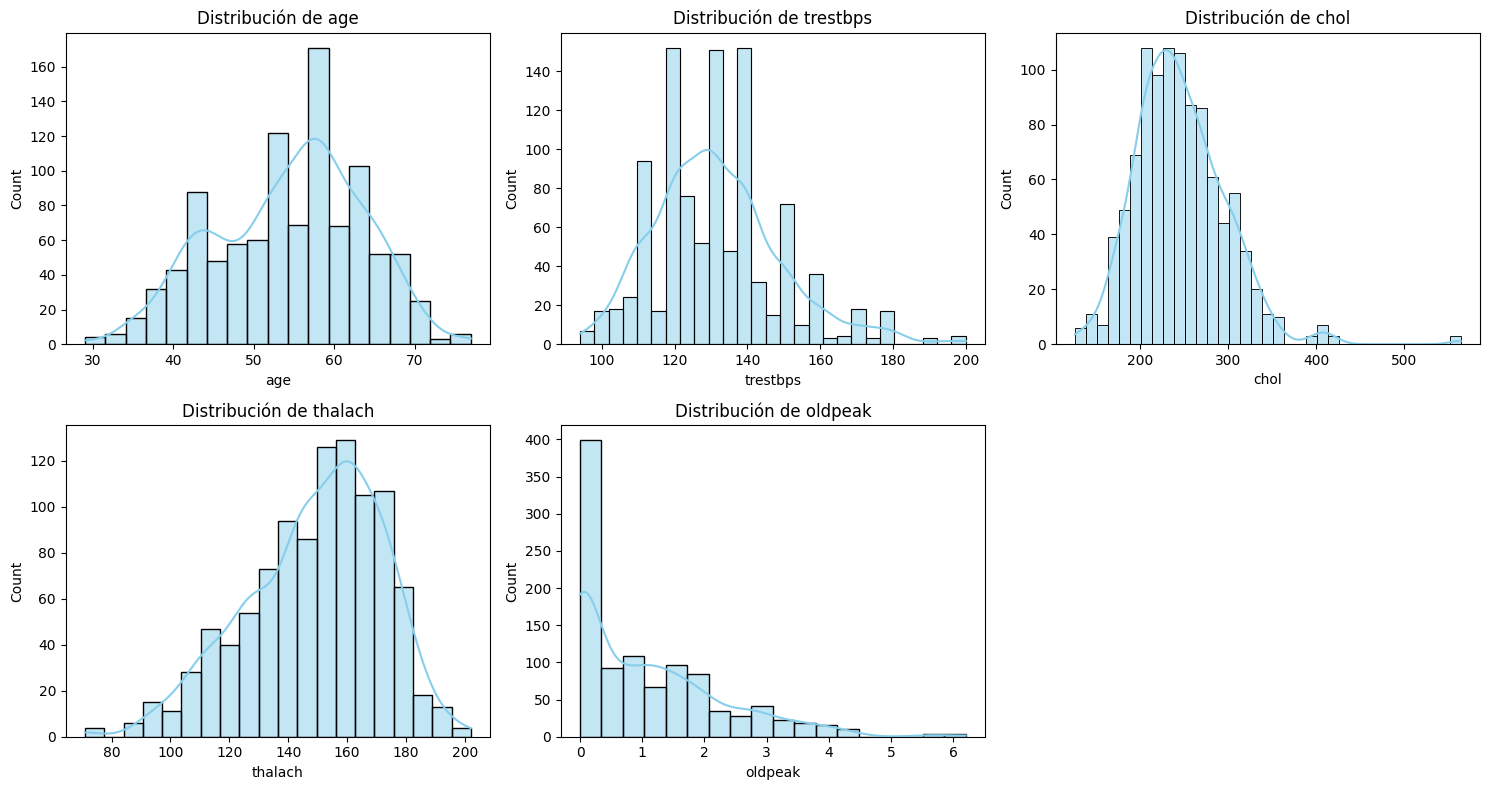

In [ ]:
cols_num = ['age','trestbps', 'chol', 'thalach', 'oldpeak']
n_cols = len(cols_num)
n_filas = math.ceil(n_cols / 3) # Define 3 gráficos por fila
fig, axes = plt.subplots(nrows=n_filas, ncols=3, figsize=(15, 4 * n_filas))
axes = axes.flatten()
for i, col in enumerate(cols_num):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True, color='skyblue')
    axes[i].set_title(f'Distribución de {col}')
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

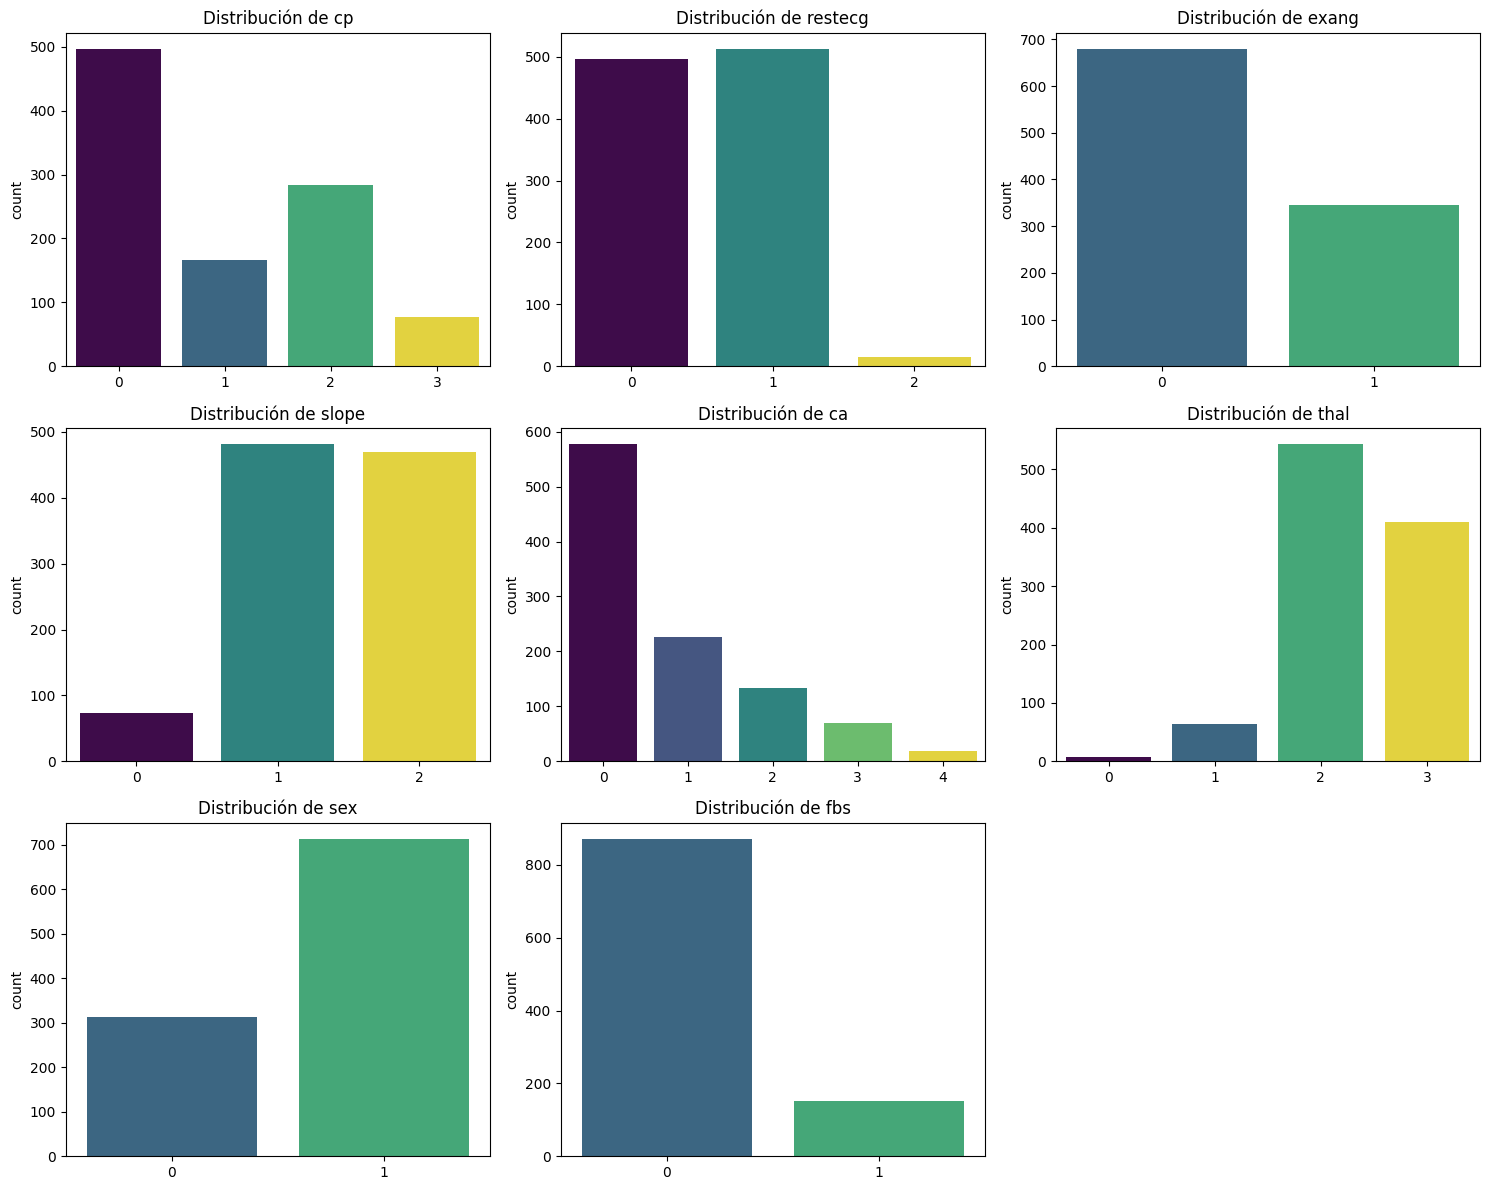

In [ ]:
columnas = ['cp', 'restecg', 'exang', 'slope', 'ca', 'thal', 'sex', 'fbs']
n_cols = len(columnas)
n_filas = math.ceil(n_cols / 3)

# Crear la cuadrícula
fig, axes = plt.subplots(nrows=n_filas, ncols=3, figsize=(15, 4 * n_filas))
axes = axes.flatten()

# Graficar cada variable con un bucle
for i, col in enumerate(columnas):
    sns.countplot(data=df, x=col, hue=col, legend=False, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Distribución de {col}')
    axes[i].set_xlabel('') # Opcional: limpia la etiqueta X para que se vea más ordenado

# Eliminar los gráficos vacíos sobrantes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

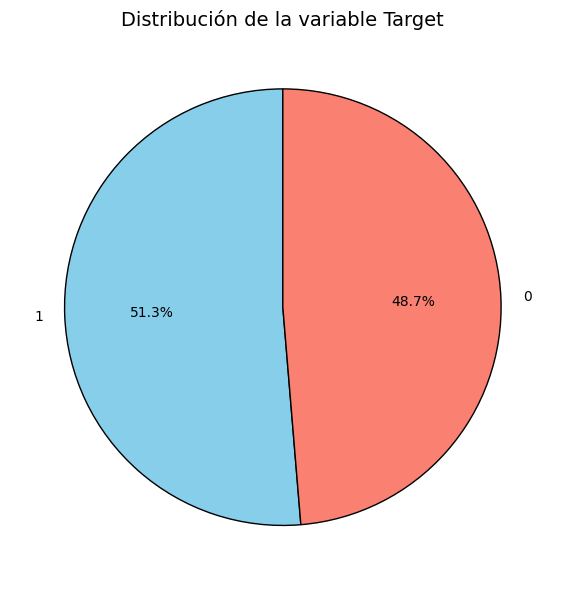

In [ ]:
conteo = df['target'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(
    conteo,
    labels=conteo.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['skyblue', 'salmon'],
    wedgeprops={'edgecolor': 'black'}
)
plt.title("Distribución de la variable Target", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
target_col = "target"
coef_skew = skew(df[target_col], bias=False)
print(f"Coeficiente de simetría de '{target_col}': {coef_skew:.4f}")
if coef_skew > 0:
    print("Distribución sesgada a la derecha (cola larga a la derecha).")
elif coef_skew < 0:
    print("Distribución sesgada a la izquierda (cola larga a la izquierda).")
else:
    print("Distribución simétrica.")

Coeficiente de simetría de 'target': -0.0528
Distribución sesgada a la izquierda (cola larga a la izquierda).


##Outliers

In [ ]:
variables_cuantitativas = ["age", "sex", "cp", "trestbps","chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"]

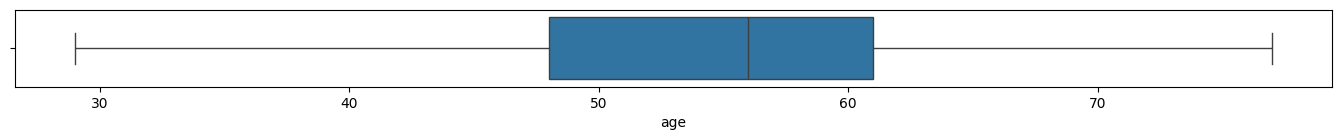

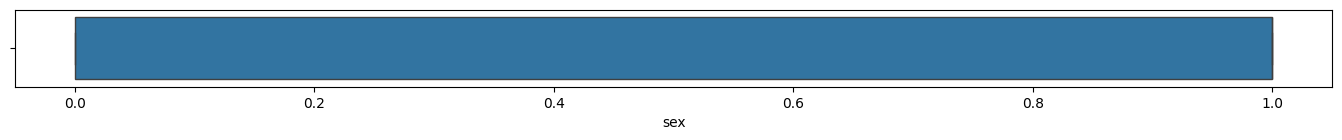

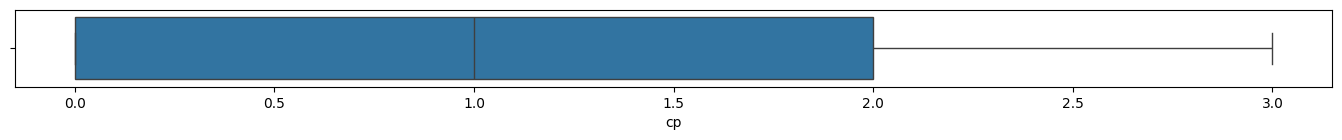

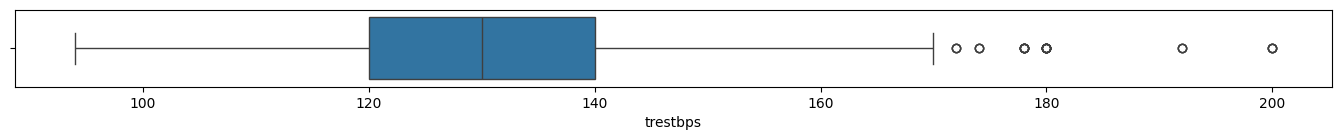

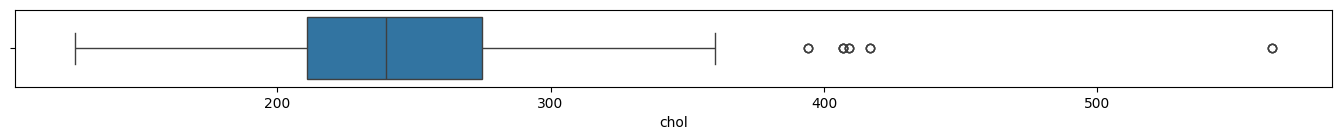

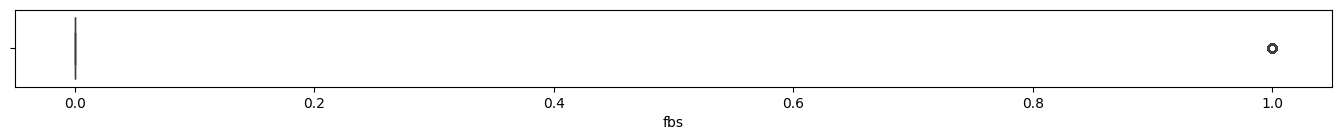

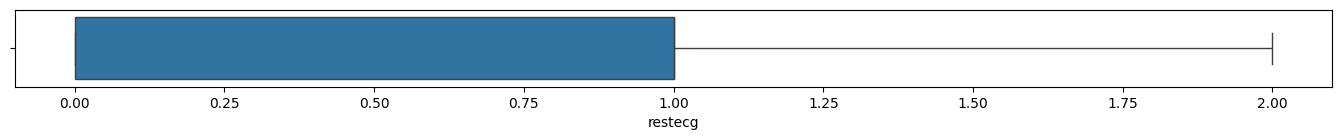

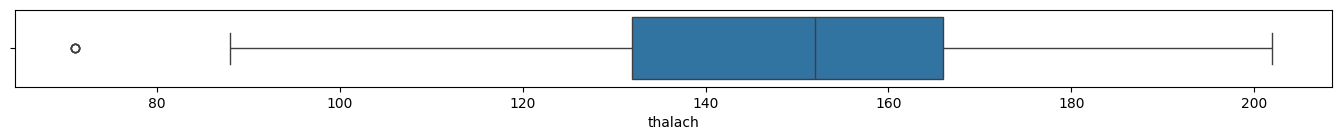

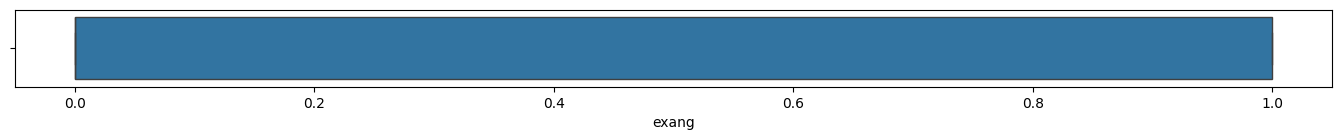

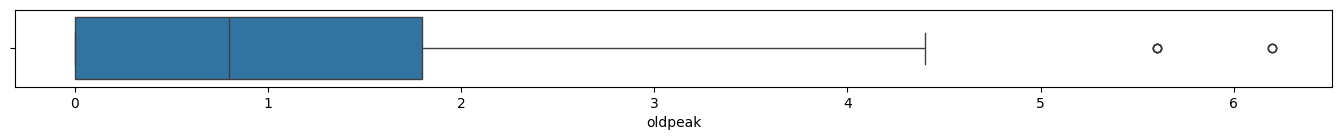

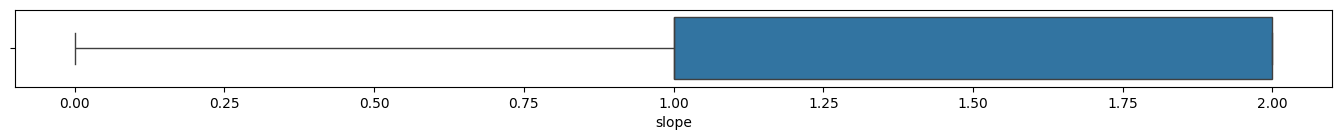

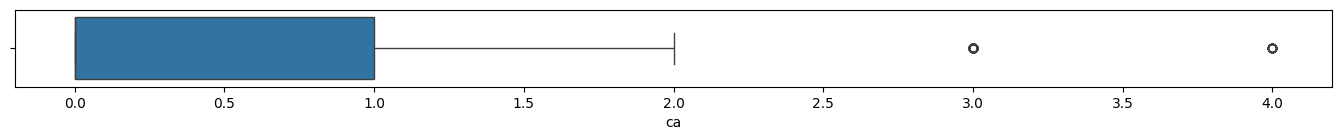

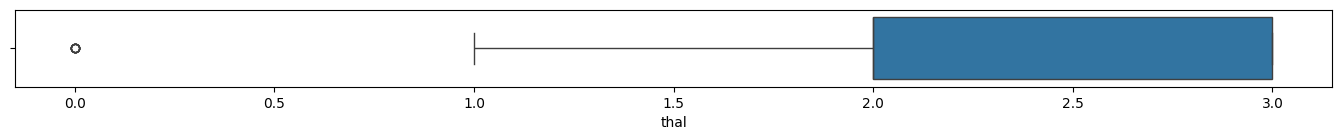

In [ ]:
#Comprobación de outliers
for col in variables_cuantitativas:
    plt.figure(figsize = (17,1))
    sns.boxplot(data=df[variables_cuantitativas], x = col)
    #Este ciclo for nos permite visualisar las columnas numéricas con su visualización bajo boxplot para ver la presencia de outliers dentro de nuestros datos


##Correlacion

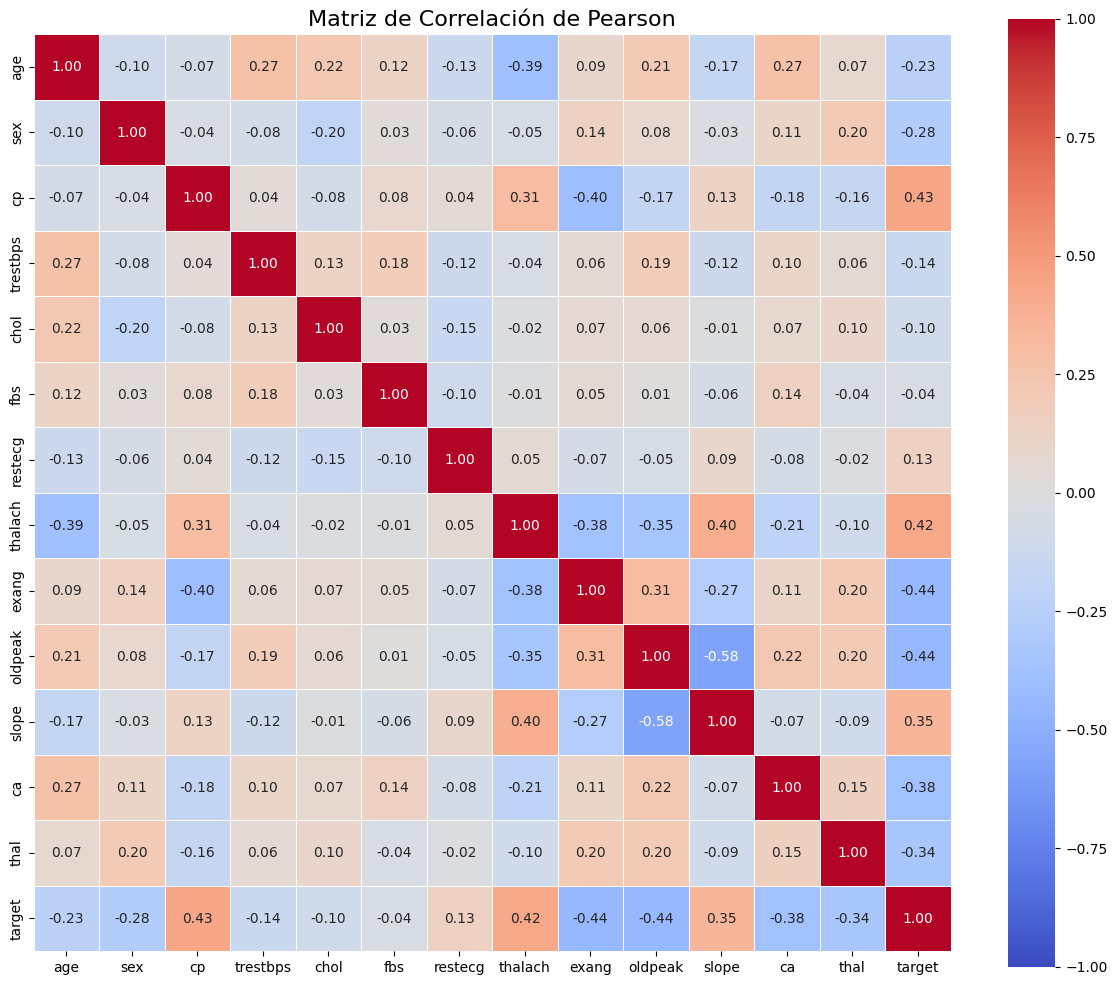

In [ ]:
df_numerico = df.select_dtypes(include=['number'])
matriz_correlacion = df_numerico.corr(method='pearson')

plt.figure(figsize=(12, 10))
sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    square=True
)
plt.title("Matriz de Correlación de Pearson", fontsize=16)
plt.tight_layout()
plt.show()

##Validacion De Datos Faltantes


In [ ]:
print(f"Datos Nulos : {df.isnull().sum().sum()}")
print(f"Datos No Validos : {df.isna().sum().sum()}")
print(f"Datos No Validos : {df.duplicated().sum()}")

Datos Nulos : 0
Datos No Validos : 0
Datos No Validos : 723


In [ ]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [ ]:
# borrar duplicados del df
df = df.drop_duplicates()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 878
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    int64  
 1   sex       302 non-null    int64  
 2   cp        302 non-null    int64  
 3   trestbps  302 non-null    int64  
 4   chol      302 non-null    int64  
 5   fbs       302 non-null    int64  
 6   restecg   302 non-null    int64  
 7   thalach   302 non-null    int64  
 8   exang     302 non-null    int64  
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    int64  
 11  ca        302 non-null    int64  
 12  thal      302 non-null    int64  
 13  target    302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 35.4 KB


##Analisis

El diseño sin identificadores personales de este dataset (1,025 registros pre limpieza y 302 post) garantiza el cumplimiento de normativas de privacidad de datos médicos, lo que permite su uso inmediato para el desarrollo de herramientas predictivas de triaje hospitalario.
Se decide no tratar sesgo por relevancia clinica, eliminarlos seria contraproducente mientras que se eliminan los 723 duplicados para evitar sesgo dentro del modelado y mantener una estabilidad y interpretavilidad alta.

## Perfil Demográfico y Variable Objetivo

* **`age` (Edad):** La población se concentra fuertemente entre los 50 y 60 años.
  > **Valor de negocio:** Define el segmento demográfico clave para campañas preventivas y asignación de presupuestos de tamizaje.
* **`sex` (Género):** Predominio masculino (69% de la muestra, desviación de 0.46).
  > **Valor de negocio:** Obliga a auditar el futuro modelo para asegurar que no subestime el riesgo cardiovascular en pacientes femeninas por falta de datos.
* **`target` (Variable Objetivo):** Distribución balanceada (~50/50).
  > **Valor de negocio:** Condición estadísticamente ideal. Permite entrenar modelos de Inteligencia Artificial sin incurrir en costos computacionales extra para balancear clases (SMOTE), garantizando métricas de éxito altamente confiables.

---

## Signos Vitales y Laboratorio

* **`trestbps` (Presión Arterial):** Media de 131.6 mmHg centrada entre 120-140, pero con valores atípicos severos hasta 200 mmHg.
  > **Valor de negocio:** Justifica la creación de reglas de negocio automatizadas que generen alertas de "código rojo" para crisis hipertensivas antes de que intervenga el modelo.
* **`chol` (Colesterol):** Media de 246 mg/dl con valores extremos cercanos a 500 mg/dl.
  > **Valor de negocio:** Identifica candidatos inmediatos para tratamientos farmacológicos agresivos (estatinas).
* **`fbs` (Glucosa):** La mayoría del tercer cuartil se mantiene sin niveles altos en ayunas.
  > **Valor de negocio:** Indica que los problemas diabéticos no son el motor principal de enfermedades en este grupo específico.

---

## Resultados de Pruebas Cardiológicas Avanzadas

* **`cp` (Dolor de Pecho):** Varianza alta (113% Aprox) fuertemente influenciada por casos asintomáticos (valor 0).
  > **Valor de negocio:** Diferenciador crítico para reducir falsos positivos en salas de urgencias por dolores no cardíacos.
* **`restecg` (Electrocardiograma):** Predominan los resultados 0 (normal) y 1 (arritmias).
  > **Valor de negocio:** Valida al ECG en reposo como el examen costo-efectivo de primera línea.
* **`thalach` (Frecuencia Cardíaca Máxima):** Sesgada a la izquierda. Frecuencias atípicamente bajas durante esfuerzo indican un sistema cardíaco ya comprometido.
* **`oldpeak` & `slope` (Segmento ST):** `oldpeak` (media en 0.8 mm) y `slope` muestran alta variabilidad.
  > **Valor de negocio:** Son los indicadores clínicos de mayor peso en las pruebas de esfuerzo; valores anormales aquí justifican derivar al paciente a angiografías costosas.
* **`exang` (Angina por Ejercicio):** Ausente en más del 50%. Cuando aparece, es un síntoma de alarma grave.
* **`ca` & `thal`:** Mayoría en parámetros normales (0). Desviaciones aquí confirman obstrucciones físicas.

---

## Análisis de Correlación (Motor Predictivo)

| Impacto en el Diagnóstico (`target`) | Variables | Interpretación Clínica y Operativa |
|---|---|---|
| **Fuerte Positiva** | `slope`, `thalach`, `cp` | **Predictores principales.** A mayor frecuencia cardíaca o dolor de pecho específico, el riesgo se dispara. Estas 3 pruebas deben priorizarse en los protocolos hospitalarios. |
| **Fuerte Negativa** | `ca`, `oldpeak`, `exang` | **Factores de deterioro.** Mayor número de vasos obstruidos y caídas del segmento ST reducen drásticamente la probabilidad de estar sano. |
| **Débil** | `thal`, `age`, `sex` | Aportan contexto demográfico, pero no diagnostican por sí solos. |
| **Nula** | `restecg`, `fbs`, `chol`, `trestbps` | **Ruido estadístico.** Al no tener relación directa lineal con el diagnóstico, el modelo podría confundirse si se dejan sin procesar. |

## Futuras Mejoras y Próximos Pasos

* **Ingeniería de Características (*Feature Engineering*):** Creación de nuevas variables con mayor valor clínico. Esto incluye agrupar a los pacientes por rango etario (ej. `<40`, `40-60`, `>60`) y categorizar los niveles de presión arterial o colesterol según estándares médicos reales para que el modelo identifique patrones de riesgo más claros.
* **Reducción de Dimensionalidad:** Selección estratégica de variables (*Feature Selection*) para conservar únicamente aquellas que aportan peso predictivo directo al `target`. Se descartarán las métricas con correlación nula para evitar el sobreajuste (*overfitting*), logrando un modelo más rápido, ligero y preciso.
* **Evaluación de Métricas Prioritarias:** Definición de los indicadores de éxito del modelo orientados al negocio. Discutirlo con el grupo.

# FASE 3: Preparación de los datos

# Preprocesamiento

In [ ]:
# se separan los datos para modelos de clasificación
X = df.drop(columns=['target'])
y = df['target']
# 4. Dividir en Entrenamiento y Prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=67, stratify=y)

In [ ]:
cols_num = ['age','trestbps', 'chol', 'thalach', 'oldpeak', 'slope', 'ca', 'thal']
cols_bin = ['sex', 'cp', 'fbs', 'exang']

In [ ]:
pipe_num = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="mean")),
        ("escalado", MinMaxScaler())
    ]
)


preprocesador = ColumnTransformer(
    transformers=[
        ("num", pipe_num, cols_num),
    ],
    remainder='passthrough', # Deja intactas las columnas que no listamos (como las binarias)
    verbose_feature_names_out=False
).set_output(transform="pandas")

In [ ]:
pipeline_base = Pipeline(steps=[
    ("duplicados", FunctionTransformer()),
    ("preprocesador", preprocesador),
    ("colinealidad", CorrelationFilter(threshold=0.9))

])

# FASE 4: Modelamiento

## LogisticRegression

### LogisticRegression solo

In [ ]:
#modelo de regresión logística base
pipeline_modelo_lr = Pipeline(steps=[
    ("preprocesamiento", pipeline_base),
    ("modelo", LogisticRegression(max_iter=1000, random_state=67))
])

In [ ]:
metricas_lr = evaluar_modelo_clasificacion(pipeline_modelo_lr, X_train, X_test, y_train, y_test)
print(f"{'Accuracy':<20}: {metricas_lr['accuracy']:.4f}")
print(f"{'F1 Score:':<20}: {metricas_lr['f1']:.4f}")
print(f"{'ROC AUC Score':<20}: {metricas_lr['roc_auc']:.4f}")
print(f"{'Precision':<20}: {metricas_lr['precision']:.4f}")
print(f"{'Recall':<20}: {metricas_lr['recall']:.4f}")

Accuracy            : 0.8033
F1 Score:           : 0.8286
ROC AUC Score       : 0.8647
Precision           : 0.7838
Recall              : 0.8788


In [ ]:
print(f"{'Score del modelo en entrenamiento':<40}:{pipeline_modelo_lr.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test': <40}:{pipeline_modelo_lr.score(X_test, y_test):.5f}")

Score del modelo en entrenamiento       :0.84232
Score del modelo en test                :0.80328


### LogisticRegression GridSearchCV

In [ ]:
param_grid_lr = [
    {
        'modelo__solver': ['lbfgs'],
        'modelo__penalty': ['l2', None],
        'modelo__C': [0.01, 0.1, 1.0, 10.0, 100.0],
        'modelo__class_weight': [None, 'balanced']
    },
    {
        'modelo__solver': ['liblinear'],
        'modelo__penalty': ['l1', 'l2'],
        'modelo__C': [0.01, 0.1, 1.0, 10.0, 100.0],
        'modelo__class_weight': [None, 'balanced']
    }
]

In [ ]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_lr = GridSearchCV(
    estimator=pipeline_modelo_lr,
    param_grid=param_grid_lr,
    scoring='roc_auc',  # Optimiza para separar adecuadamente ambas clases
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

# Entrenamiento de la búsqueda
grid_lr.fit(X_train, y_train)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocesamiento',
                                        Pipeline(steps=[('duplicados',
                                                         FunctionTransformer()),
                                                        ('preprocesador',
                                                         ColumnTransformer(remainder='passthrough',
                                                                           transformers=[('num',
                                                                                          Pipeline(steps=[('imputacion',
                                                                                                           SimpleImputer()),
                                                                                                          ('escalado',
                                                                                                           MinMaxScaler())]),
                                                                                          ['age',
                                                                                           'trestbps',
                                                                                           'ch...
                                                           random_state=67))]),
             n_jobs=-1,
             param_grid=[{'modelo__C': [0.01, 0.1, 1.0, 10.0, 100.0],
                          'modelo__class_weight': [None, 'balanced'],
                          'modelo__penalty': ['l2', None],
                          'modelo__solver': ['lbfgs']},
                         {'modelo__C': [0.01, 0.1, 1.0, 10.0, 100.0],
                          'modelo__class_weight': [None, 'balanced'],
                          'modelo__penalty': ['l1', 'l2'],
                          'modelo__solver': ['liblinear']}],
             scoring='roc_auc', verbose=1)

In [ ]:
print(f"{'Mejores parámetros':<20}: {grid_lr.best_params_}")
print(f"{'Mejor score':<20}:{grid_lr.best_score_:.4f}")

Mejores parámetros  : {'modelo__C': 1.0, 'modelo__class_weight': 'balanced', 'modelo__penalty': 'l2', 'modelo__solver': 'lbfgs'}
Mejor score         :0.8901


In [ ]:
modelo_lr_grid = grid_lr.best_estimator_

In [ ]:
metricas_lr_mejor = evaluar_modelo_clasificacion(modelo_lr_grid, X_train, X_test, y_train, y_test)
print(f"{'Accuracy':<20}: {metricas_lr_mejor['accuracy']:.4f}")
print(f"{'F1 Score:':<20}: {metricas_lr_mejor['f1']:.4f}")
print(f"{'ROC AUC Score':<20}: {metricas_lr_mejor['roc_auc']:.4f}")
print(f"{'Precision':<20}: {metricas_lr_mejor['precision']:.4f}")
print(f"{'Recall':<20}: {metricas_lr_mejor['recall']:.4f}")

Accuracy            : 0.8033
F1 Score:           : 0.8286
ROC AUC Score       : 0.8658
Precision           : 0.7838
Recall              : 0.8788


In [ ]:
print(f"{'Score del modelo en entrenamiento':<40}:{modelo_lr_grid.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test': <40}:{modelo_lr_grid.score(X_test, y_test):.5f}")

Score del modelo en entrenamiento       :0.85477
Score del modelo en test                :0.80328


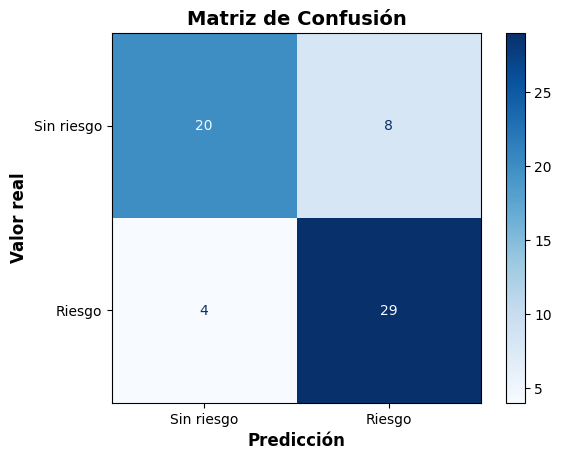

In [ ]:
y_pred = modelo_lr_grid.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Sin riesgo", "Riesgo"])
disp.plot(cmap="Blues")
plt.title("Matriz de Confusión", fontweight="bold", fontsize=14)
plt.xlabel("Predicción", fontweight="bold", fontsize=12)
plt.ylabel("Valor real", fontweight="bold", fontsize=12)
plt.show()

## RandomForest

### RandomForest solo

In [ ]:
pipeline_rf = Pipeline(steps=[
    ("preprocesador", preprocesador),
    ("modelo", RandomForestClassifier())
])

In [ ]:
# Evaluación Base
metricas_rf = evaluar_modelo_clasificacion(pipeline_rf, X_train, X_test, y_train, y_test)
print(f"{'Accuracy':<20}: {metricas_rf['accuracy']:.4f}")
print(f"{'F1 Score:':<20}: {metricas_rf['f1']:.4f}")
print(f"{'ROC AUC Score':<20}: {metricas_rf['roc_auc']:.4f}")
print(f"{'Precision':<20}: {metricas_rf['precision']:.4f}")
print(f"{'Recall':<20}: {metricas_rf['recall']:.4f}")

Accuracy            : 0.8033
F1 Score:           : 0.8286
ROC AUC Score       : 0.9021
Precision           : 0.7838
Recall              : 0.8788


### RandomForest GridSearchCV

In [ ]:
# 1. PIPELINE PARA GRIDSEARCH
pipeline_gs = Pipeline(steps=[
    ("preprocesador", preprocesador),
    ("modelo", RandomForestClassifier(random_state=42, n_jobs=-1))
])

In [ ]:
# 2. DEFINICIÓN DE LA REJILLA DE HIPERPARÁMETROS
param_grid_rf = {
    'modelo__n_estimators': [100, 200],          # Cantidad de árboles en el bosque
    'modelo__max_depth': [8, 12, 16],             # Límite de profundidad para evitar overfitting
    'modelo__min_samples_split': [10, 20, 30],   # Muestras necesarias para abrir un nuevo nodo
    'modelo__min_samples_leaf': [5, 10, 15],     # Muestras mínimas por hoja terminal
    'modelo__class_weight': [None, 'balanced']    # Manejo de desbalance en la fuga de clientes
}

In [ ]:
# 3. ESTRATEGIA DE VALIDACIÓN CRUZADA Y CONFIGURACIÓN DE BÚSQUEDA
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_rf = GridSearchCV(
    estimator=pipeline_gs,
    param_grid=param_grid_rf,
    scoring='roc_auc',  # Optimiza el área bajo la curva ROC (métrica clave en fuga)
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

In [ ]:
# 4. ENTRENAMIENTO Y EVALUACIÓN
print("Iniciando búsqueda de hiperparámetros...")
grid_rf.fit(X_train, y_train)

print("\n" + "="*50)
print(" RESULTADOS GRIDSEARCHCV - RANDOM FOREST ")
print("="*50)
print(f"Mejores hiperparámetros encontrados:\n{grid_rf.best_params_}")
print(f"Mejor ROC-AUC en Validación Cruzada: {grid_rf.best_score_:.4f}")

Iniciando búsqueda de hiperparámetros...
Fitting 5 folds for each of 108 candidates, totalling 540 fits

 RESULTADOS GRIDSEARCHCV - RANDOM FOREST 
Mejores hiperparámetros encontrados:
{'modelo__class_weight': None, 'modelo__max_depth': 8, 'modelo__min_samples_leaf': 15, 'modelo__min_samples_split': 10, 'modelo__n_estimators': 100}
Mejor ROC-AUC en Validación Cruzada: 0.9091


In [ ]:
# Evaluación en Test Set con el Mejor Estimador
mejor_rf = grid_rf.best_estimator_
y_pred_gs = mejor_rf.predict(X_test)
y_proba_gs = mejor_rf.predict_proba(X_test)[:, 1]

metricas_rf_mejor = evaluar_modelo_clasificacion(mejor_rf, X_train, X_test, y_train, y_test)
print(f"{'Accuracy':<20}: {metricas_rf_mejor['accuracy']:.4f}")
print(f"{'F1 Score:':<20}: {metricas_rf_mejor['f1']:.4f}")
print(f"{'ROC AUC Score':<20}: {metricas_rf_mejor['roc_auc']:.4f}")
print(f"{'Precision':<20}: {metricas_rf_mejor['precision']:.4f}")
print(f"{'Recall':<20}: {metricas_rf_mejor['recall']:.4f}")

Accuracy            : 0.8525
F1 Score:           : 0.8732
ROC AUC Score       : 0.8853
Precision           : 0.8158
Recall              : 0.9394


In [ ]:
print(classification_report(y_test, y_pred_gs))

              precision    recall  f1-score   support

           0       0.91      0.75      0.82        28
           1       0.82      0.94      0.87        33

    accuracy                           0.85        61
   macro avg       0.86      0.84      0.85        61
weighted avg       0.86      0.85      0.85        61



In [ ]:
print(f"{'Score del modelo en entrenamiento':<40}:{mejor_rf.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test': <40}:{mejor_rf.score(X_test, y_test):.5f}")

Score del modelo en entrenamiento       :0.87137
Score del modelo en test                :0.85246


## DecissionTree

### DecissionTree solo

In [ ]:
pipeline_dt = Pipeline(steps=[
    ("preprocesador", preprocesador),
    ("modelo", DecisionTreeClassifier())
])

In [ ]:
# Evaluación Base
metricas_dt = evaluar_modelo_clasificacion(pipeline_dt, X_train, X_test, y_train, y_test)
print(f"{'Accuracy':<20}: {metricas_dt['accuracy']:.4f}")
print(f"{'F1 Score:':<20}: {metricas_dt['f1']:.4f}")
print(f"{'ROC AUC Score':<20}: {metricas_dt['roc_auc']:.4f}")
print(f"{'Precision':<20}: {metricas_dt['precision']:.4f}")
print(f"{'Recall':<20}: {metricas_dt['recall']:.4f}")

Accuracy            : 0.7049
F1 Score:           : 0.7353
ROC AUC Score       : 0.7002
Precision           : 0.7143
Recall              : 0.7576


### DecissionTree GridSearchCV

In [ ]:
pipeline_gs_dt = Pipeline(steps=[
    ("preprocesador", preprocesador),
    ("modelo", DecisionTreeClassifier(random_state=42))
])

In [ ]:
param_grid_dt = {
    'modelo__criterion': ['gini', 'entropy'],
    'modelo__max_depth': [4, 6, 8, 10, 12],
    'modelo__min_samples_split': [10, 20, 50, 100],
    'modelo__min_samples_leaf': [5, 10, 20, 40],
    'modelo__class_weight': [None, 'balanced'] # Ajuste para equilibrar falsos positivos y negativos
}

In [ ]:
# Se utiliza StratifiedKFold para mantener la proporción de la variable Exit (0/1)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_dt = GridSearchCV(
    estimator=pipeline_gs_dt,
    param_grid=param_grid_dt,
    scoring='roc_auc',  # Maximiza la separación entre pacientes con riesgo y sin riesgo
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

In [ ]:
print("Iniciando GridSearchCV para DecisionTreeClassifier...")
grid_dt.fit(X_train, y_train)

print("\n" + "="*50)
print(" RESULTADOS GRIDSEARCHCV - ÁRBOL DE DECISIÓN ")
print("="*50)
print(f"Mejores hiperparámetros encontrados:\n{grid_dt.best_params_}")
print(f"Mejor ROC-AUC en Validación Cruzada: {grid_dt.best_score_:.4f}")

Iniciando GridSearchCV para DecisionTreeClassifier...
Fitting 5 folds for each of 320 candidates, totalling 1600 fits

 RESULTADOS GRIDSEARCHCV - ÁRBOL DE DECISIÓN 
Mejores hiperparámetros encontrados:
{'modelo__class_weight': None, 'modelo__criterion': 'gini', 'modelo__max_depth': 6, 'modelo__min_samples_leaf': 5, 'modelo__min_samples_split': 20}
Mejor ROC-AUC en Validación Cruzada: 0.8453


In [ ]:
mejor_arbol = grid_dt.best_estimator_

# Evaluación
metricas_dt_mejor = evaluar_modelo_clasificacion(mejor_arbol, X_train, X_test, y_train, y_test)
print(f"{'Accuracy':<20}: {metricas_dt_mejor['accuracy']:.4f}")
print(f"{'F1 Score:':<20}: {metricas_dt_mejor['f1']:.4f}")
print(f"{'ROC AUC Score':<20}: {metricas_dt_mejor['roc_auc']:.4f}")
print(f"{'Precision':<20}: {metricas_dt_mejor['precision']:.4f}")
print(f"{'Recall':<20}: {metricas_dt_mejor['recall']:.4f}")

Accuracy            : 0.7869
F1 Score:           : 0.8267
ROC AUC Score       : 0.8528
Precision           : 0.7381
Recall              : 0.9394


# Predicción dato nuevo

In [ ]:
def generar_datos_cardiacos(n_samples=100, seed=42):
    np.random.seed(seed)

    df_nuevo = pd.DataFrame(
        {
            "age": np.random.randint(29, 78, size=n_samples),
            "sex": np.random.choice([0, 1], size=n_samples),
            "cp": np.random.choice([0, 1, 2, 3], size=n_samples),
            "trestbps": np.random.randint(94, 201, size=n_samples),
            "chol": np.random.randint(126, 565, size=n_samples),
            "fbs": np.random.choice([0, 1], size=n_samples),
            "restecg": np.random.choice([0, 1, 2], size=n_samples),
            "thalach": np.random.randint(71, 203, size=n_samples),
            "exang": np.random.choice([0, 1], size=n_samples),
            "oldpeak": np.round(
                np.random.uniform(0.0, 6.2, size=n_samples), 1
            ),
            "slope": np.random.choice([0, 1, 2], size=n_samples),
            "ca": np.random.choice([0, 1, 2, 3], size=n_samples),
            "thal": np.random.choice([0, 1, 2, 3], size=n_samples),
        }
    )

    return df_nuevo


# Generación de 40 registros sintéticos
df_sintetico = generar_datos_cardiacos(n_samples=40, seed=42)

In [ ]:
# 2. Obtener la predicción binaria directa (retorna 0 o 1, o la etiqueta de la clase)
prediccion_clase = mejor_rf.predict(df_sintetico)
print(f"Resultado binario directo: {prediccion_clase[0]}")

# 3. Obtener la probabilidad estimada para la clase positiva (Clase 1)
probabilidades = mejor_rf.predict_proba(df_sintetico)
probabilidad_exito = probabilidades[0, 1]  # Columna 1 corresponde a la clase positiva
print(f"Probabilidad de pertenecer a la clase 1: {probabilidad_exito:.2%}")

Resultado binario directo: 0
Probabilidad de pertenecer a la clase 1: 33.56%


In [ ]:
#Recorrer fila por fila con bucle for haciendo la predicción individual
for i in range(len(df_sintetico)):
    # Extraer el registro individual como DataFrame (mantiene columnas y tipos de datos)
    registro = df_sintetico.iloc[[i]]

    # Predicción con el modelo mejor_rf (0 o 1)
    prediccion = mejor_rf.predict(registro)[0]
    estado_riesgo = (
        "Riesgo Cardíaco (1)" if prediccion == 1 else "Sin Riesgo (0)"
    )

    # Desplegar datos de la persona y el resultado
    print(f"=== Registro {i+1} ===")
    print(f"Datos del paciente: {registro.to_dict(orient='records')[0]}")
    print(f"Resultado Predicho : {prediccion} -> {estado_riesgo}\n")

=== Registro 1 ===
Datos del paciente: {'age': 67, 'sex': 0, 'cp': 1, 'trestbps': 101, 'chol': 380, 'fbs': 1, 'restecg': 0, 'thalach': 167, 'exang': 1, 'oldpeak': 2.7, 'slope': 1, 'ca': 3, 'thal': 3}
Resultado Predicho : 0 -> Sin Riesgo (0)

=== Registro 2 ===
Datos del paciente: {'age': 57, 'sex': 0, 'cp': 3, 'trestbps': 181, 'chol': 523, 'fbs': 1, 'restecg': 0, 'thalach': 194, 'exang': 1, 'oldpeak': 2.2, 'slope': 2, 'ca': 0, 'thal': 0}
Resultado Predicho : 1 -> Riesgo Cardíaco (1)

=== Registro 3 ===
Datos del paciente: {'age': 43, 'sex': 0, 'cp': 1, 'trestbps': 156, 'chol': 484, 'fbs': 1, 'restecg': 1, 'thalach': 140, 'exang': 1, 'oldpeak': 4.0, 'slope': 1, 'ca': 3, 'thal': 0}
Resultado Predicho : 0 -> Sin Riesgo (0)

=== Registro 4 ===
Datos del paciente: {'age': 71, 'sex': 1, 'cp': 1, 'trestbps': 104, 'chol': 408, 'fbs': 1, 'restecg': 0, 'thalach': 163, 'exang': 1, 'oldpeak': 4.1, 'slope': 2, 'ca': 3, 'thal': 1}
Resultado Predicho : 1 -> Riesgo Cardíaco (1)

=== Registro 5 ===
Dat

In [ ]:
df_sintetico

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,67,0,1,101,380,1,0,167,1,2.7,1,3,3
1,57,0,3,181,523,1,0,194,1,2.2,2,0,0
2,43,0,1,156,484,1,1,140,1,4.0,1,3,0
3,71,1,1,104,408,1,0,163,1,4.1,2,3,1
4,36,1,1,174,518,1,1,73,0,5.4,1,3,1
5,49,0,3,101,332,0,1,160,1,1.4,0,0,0
6,67,1,1,128,140,1,2,166,0,3.1,0,2,2
7,47,1,2,128,471,1,1,122,0,3.5,1,3,1
8,51,1,3,126,167,0,2,198,1,4.8,2,1,3
9,39,1,2,98,505,1,0,109,0,0.3,0,0,1


# FASE 5: Evaluación del modelo

In [ ]:
# Tabla comparativa de modelos
UMBRAL_RECALL = 0.90

resultados = {
    "Regresión Logística (base)":       metricas_lr,
    "Regresión Logística (GridSearch)": metricas_lr_mejor,
    "Random Forest (base)":             metricas_rf,
    "Random Forest (GridSearch)":       metricas_rf_mejor,
    "Árbol de Decisión (base)":         metricas_dt,
    "Árbol de Decisión (GridSearch)":   metricas_dt_mejor,
}

tabla = pd.DataFrame(resultados).T[["accuracy", "precision", "recall", "f1", "roc_auc"]]
tabla.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC AUC"]
tabla["Cumple recall ≥ 90%"] = np.where(tabla["Recall"] >= UMBRAL_RECALL, "Sí", "No")
display(tabla.round(4))


print("\nVerificación del criterio de sensibilidad (modelos optimizados):")
finales = tabla.loc[[n for n in tabla.index if "GridSearch" in n]]
for nombre, fila in finales.iterrows():
    estado = "CUMPLE" if fila["Recall"] >= UMBRAL_RECALL else "NO CUMPLE"
    print(f"  {nombre:<36} recall = {fila['Recall']:.4f} -> {estado}")


candidatos = finales[finales["Recall"] >= UMBRAL_RECALL]
if candidatos.empty:
    print("\nNingún modelo alcanza el recall mínimo: hay que iterar (umbral de decisión, más variables, otros modelos).")
else:
    modelo_elegido = candidatos["F1"].idxmax()
    print(f"\nModelo seleccionado: {modelo_elegido} (mayor F1 entre los que cumplen el recall mínimo)")

,Accuracy,Precision,Recall,F1,ROC AUC,Cumple recall ≥ 90%
Regresión Logística (base),0.8033,0.7838,0.8788,0.8286,0.8647,No
Regresión Logística (GridSearch),0.8033,0.7838,0.8788,0.8286,0.8658,No
Random Forest (base),0.8033,0.7838,0.8788,0.8286,0.9021,No
Random Forest (GridSearch),0.8525,0.8158,0.9394,0.8732,0.8853,Sí
Árbol de Decisión (base),0.7049,0.7143,0.7576,0.7353,0.7002,No
Árbol de Decisión (GridSearch),0.7869,0.7381,0.9394,0.8267,0.8528,Sí



Verificación del criterio de sensibilidad (modelos optimizados):
  Regresión Logística (GridSearch)     recall = 0.8788 -> NO CUMPLE
  Random Forest (GridSearch)           recall = 0.9394 -> CUMPLE
  Árbol de Decisión (GridSearch)       recall = 0.9394 -> CUMPLE

Modelo seleccionado: Random Forest (GridSearch) (mayor F1 entre los que cumplen el recall mínimo)


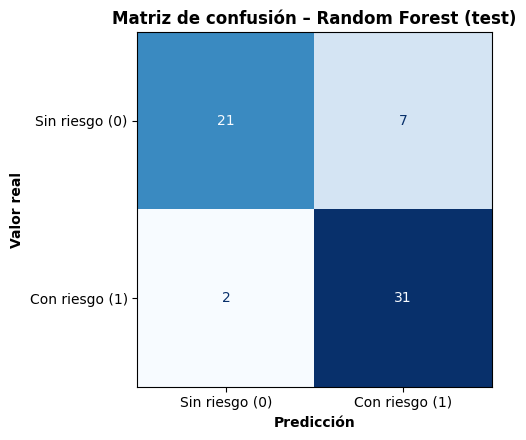

Verdaderos positivos (riesgo detectado)  : 31
Falsos negativos (riesgo NO detectado)   : 2    error más costoso
Falsos positivos (falsa alarma)          : 7
Verdaderos negativos                     : 21

recall  : 0.9394
Especificidad          : 0.7500


In [ ]:
#  Matriz de confusión del modelo seleccionado (Random Forest optimizado)
y_pred_rf = mejor_rf.predict(X_test)
cm_rf = confusion_matrix(y_test, y_pred_rf)
tn, fp, fn, tp = cm_rf.ravel()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm_rf, display_labels=["Sin riesgo (0)", "Con riesgo (1)"]).plot(
    cmap="Blues", ax=ax, colorbar=False
)
ax.set_title("Matriz de confusión – Random Forest (test)", fontweight="bold")
ax.set_xlabel("Predicción", fontweight="bold")
ax.set_ylabel("Valor real", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Verdaderos positivos (riesgo detectado)  : {tp}")
print(f"Falsos negativos (riesgo NO detectado)   : {fn}    error más costoso")
print(f"Falsos positivos (falsa alarma)          : {fp}")
print(f"Verdaderos negativos                     : {tn}")
print(f"\nrecall  : {tp / (tp + fn):.4f}")
print(f"Especificidad          : {tn / (tn + fp):.4f}")

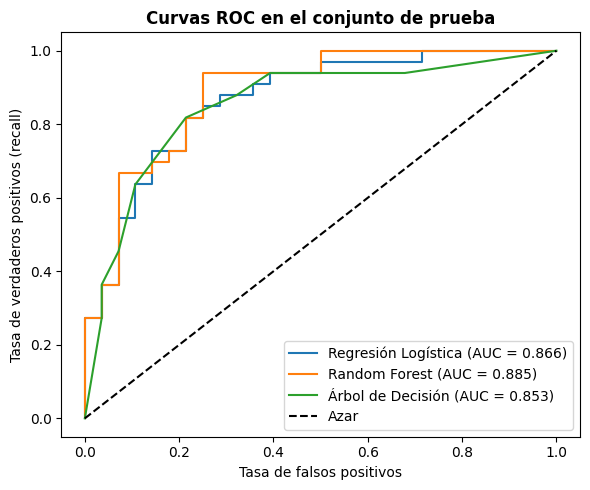

In [ ]:
# Curvas ROC de los tres modelos optimizados
modelos_finales = {
    "Regresión Logística": modelo_lr_grid,
    "Random Forest":       mejor_rf,
    "Árbol de Decisión":   mejor_arbol,
}

fig, ax = plt.subplots(figsize=(6, 5))
for nombre, modelo in modelos_finales.items():
    prob = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_test, prob):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Azar")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title("Curvas ROC en el conjunto de prueba", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
# Desempeño por grupo (sexo)
filas = []
for valor, etiqueta in [(0, "Mujeres"), (1, "Hombres")]:
    mascara = (X_test["sex"] == valor).values
    yt, yp = y_test[mascara], y_pred_rf[mascara]
    filas.append({
        "Grupo": etiqueta,
        "Pacientes en test": int(mascara.sum()),
        "Con riesgo real": int((yt == 1).sum()),
        "Recall": recall_score(yt, yp) if (yt == 1).sum() > 0 else np.nan,
        "Precision": precision_score(yt, yp, zero_division=0),
        "Accuracy": accuracy_score(yt, yp),
    })
display(pd.DataFrame(filas).round(3))

,Grupo,Pacientes en test,Con riesgo real,Recall,Precision,Accuracy
0,Mujeres,21,17,1.000,0.944,0.952
1,Hombres,40,16,0.875,0.700,0.800


El sexo de mujer denota metricas altas debido a la naturaleza del dataset...tener esto en consideracion chiquis.

Analisis:
* Regresión logística (optimizada): recall = 0,879  no cumple la meta de sensibilidad ≥ 90 %.
* Random Forest (optimizado): recall = 0,939 (2 falsos negativos sobre 33 pacientes con riesgo), accuracy = 0,852, F1 = 0,873, ROC AUC = 0,885 → cumple la meta y es el modelo con mejor equilibrio entre sensibilidad y precisión.
* Árbol de decisión (optimizado): recall = 0,939, también cumple, pero con precisión 0,738 y accuracy 0,787, es decir, más falsas alarmas.
* Decisión: se selecciona el Random Forest optimizado como modelo para el despliegue.

Limitaciones:
* El conjunto de prueba tiene solo 61 pacientes (31 con riesgo): un solo paciente mal clasificado mueve el recall unos 3 puntos, por lo que la meta del 90 % se cumple con alta incertidumbre.
* Tras eliminar duplicados el dataset queda en 302 registros y predomina la población masculina; el desempeño por sexo (5.4) se calcula con muy pocos casos femeninos.


# FASE 6: Despliegue

El despliegue de esta etapa es un **panel dentro del notebook** (matplotlib) con dos partes:

1. **Panel de indicadores clínicos:** resumen de la población, riesgo por grupo de edad, desempeño del modelo frente a la meta del 90 % y principales factores de riesgo.

**Alcance:** prototipo con datos públicos (UCI). No incluye conexión a datos del hospital, seguridad ni publicación en servidores, y no está validado clínicamente.

INDICADORES GENERALES
  Pacientes analizados        : 302
  Pacientes con riesgo        : 54.3%
  Edad promedio               : 54.4 años
  Colesterol promedio         : 246 mg/dl
  Presión arterial promedio   : 132 mmHg


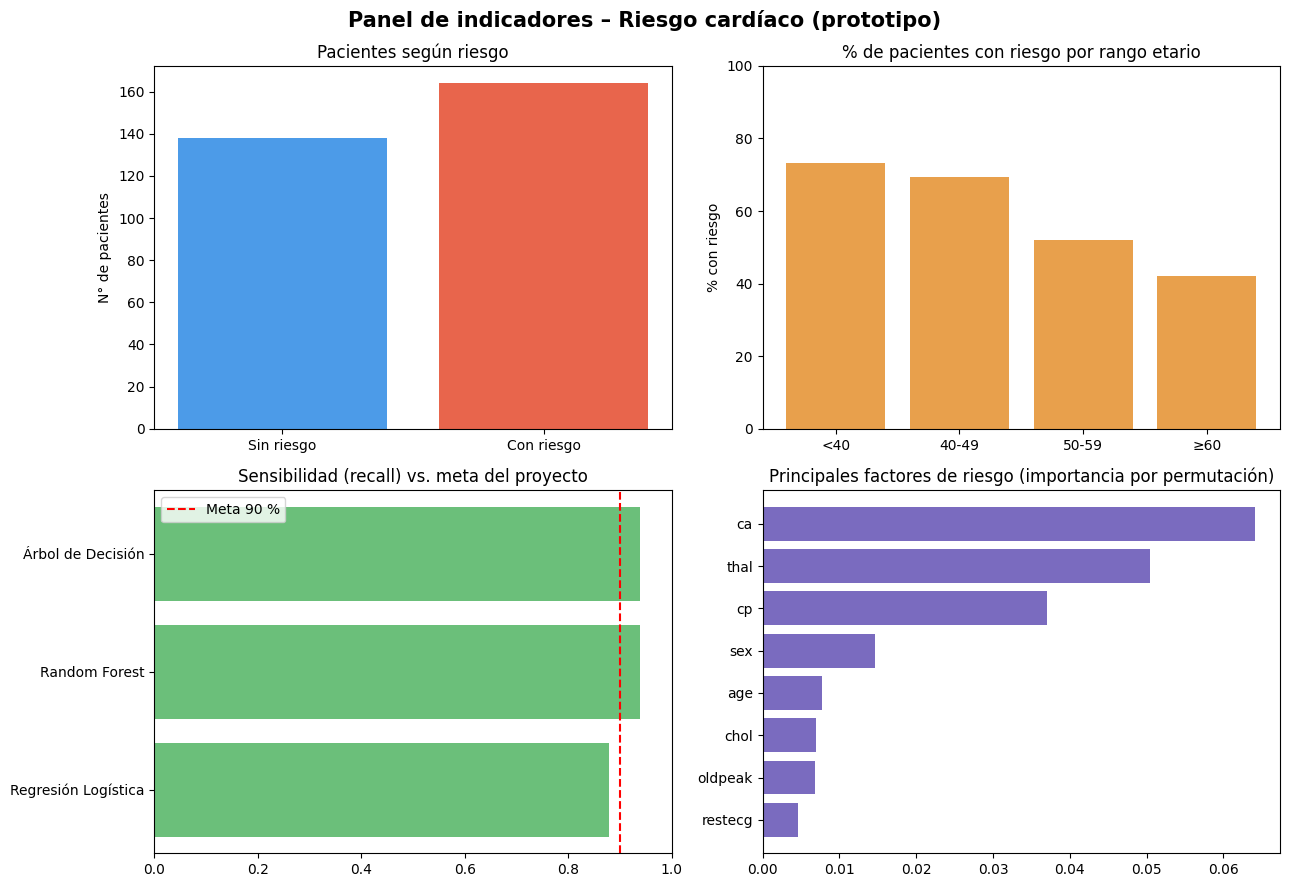

In [ ]:
# Panel de indicadores clínicos

# Importancia de variables por permutación (sobre el conjunto de prueba)
imp = permutation_importance(mejor_rf, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=42)
importancias = (pd.DataFrame({"variable": X_test.columns, "importancia": imp.importances_mean})
                .sort_values("importancia", ascending=False))

grupos_edad = pd.cut(df["age"], bins=[0, 39, 49, 59, 120], labels=["<40", "40-49", "50-59", "≥60"])
riesgo_edad = df.groupby(grupos_edad, observed=True)["target"].mean() * 100
conteo = df["target"].value_counts().sort_index()

print("INDICADORES GENERALES")
print(f"  Pacientes analizados        : {len(df)}")
print(f"  Pacientes con riesgo        : {df['target'].mean():.1%}")
print(f"  Edad promedio               : {df['age'].mean():.1f} años")
print(f"  Colesterol promedio         : {df['chol'].mean():.0f} mg/dl")
print(f"  Presión arterial promedio   : {df['trestbps'].mean():.0f} mmHg")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Distribución de la variable objetivo
axes[0, 0].bar(["Sin riesgo", "Con riesgo"], conteo.values, color=["#4c9be8", "#e8654c"])
axes[0, 0].set_title("Pacientes según riesgo")
axes[0, 0].set_ylabel("N° de pacientes")

# Tasa de riesgo por rango etario
axes[0, 1].bar(riesgo_edad.index.astype(str), riesgo_edad.values, color="#e8a04c")
axes[0, 1].set_title("% de pacientes con riesgo por rango etario")
axes[0, 1].set_ylabel("% con riesgo")
axes[0, 1].set_ylim(0, 100)

# Recall de los modelos optimizados frente a la meta del 90 %
rec = finales["Recall"]
axes[1, 0].barh([n.replace(" (GridSearch)", "") for n in rec.index], rec.values, color="#6bbf7a")
axes[1, 0].axvline(UMBRAL_RECALL, color="red", linestyle="--", label="Meta 90 %")
axes[1, 0].set_xlim(0, 1)
axes[1, 0].set_title("Sensibilidad (recall) vs. meta del proyecto")
axes[1, 0].legend()

# Variables que más influyen en el modelo
top = importancias.head(8).iloc[::-1]
axes[1, 1].barh(top["variable"], top["importancia"], color="#7a6bbf")
axes[1, 1].set_title("Principales factores de riesgo (importancia por permutación)")

fig.suptitle("Panel de indicadores – Riesgo cardíaco (prototipo)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

Mediante el analisis del grafico "% con riesgo por rango etario" se visualiza una disminucion a medida que que se aumenta, dato que clinicamente es cuestionable y denota informacion sacada del dataset, mas no de la vida real....cabe recalcar...

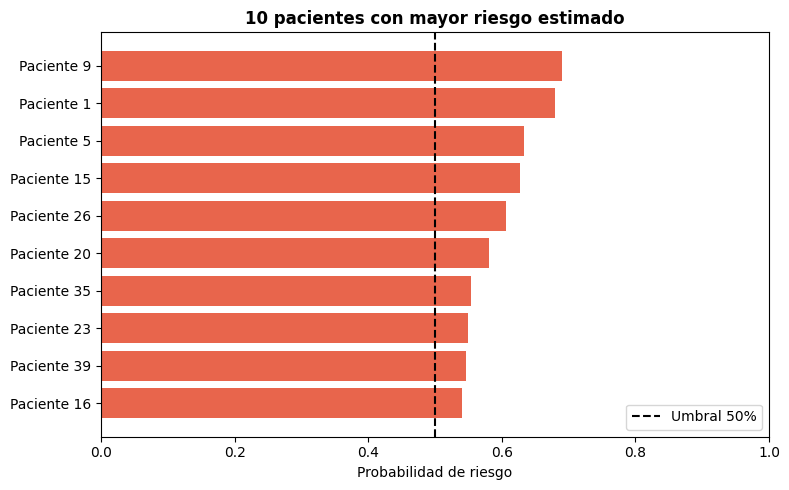

In [ ]:
UMBRAL_ALERTA = 0.5
df_prioridad = df_sintetico.copy()
df_prioridad["prob_riesgo"] = mejor_rf.predict_proba(df_sintetico)[:, 1]
top10 = df_prioridad.sort_values("prob_riesgo", ascending=False).head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
colores = ["#e8654c" if p >= UMBRAL_ALERTA else "#6bbf7a" for p in top10["prob_riesgo"]]
ax.barh([f"Paciente {i}" for i in top10.index], top10["prob_riesgo"], color=colores)
ax.axvline(UMBRAL_ALERTA, color="black", linestyle="--", label=f"Umbral {UMBRAL_ALERTA:.0%}")
ax.set_xlim(0, 1)
ax.set_xlabel("Probabilidad de riesgo")
ax.set_title("10 pacientes con mayor riesgo estimado", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()